In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:

data = {
    "study_hours": [1, 2, 3, 4, 5, 6, 7, 8, 2, 3, 5, 7, 1, 4, 6, 8, 3, 5, 7, 9],
    "attendance": [40, 45, 50, 55, 60, 65, 70, 90, 50, 55, 75, 85, 35, 60, 80, 95, 45, 70, 85, 98],
    "previous_score": [30, 35, 40, 45, 50, 55, 65, 85, 38, 42, 70, 80, 25, 48, 75, 90, 40, 65, 82, 95],
    "result": [0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1]
}

df = pd.DataFrame(data)

df.head()


,study_hours,attendance,previous_score,result
0,1,40,30,0
1,2,45,35,0
2,3,50,40,0
3,4,55,45,0
4,5,60,50,0


In [3]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nResult counts:")
print(df["result"].value_counts())

Dataset shape: (20, 4)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   study_hours     20 non-null     int64
 1   attendance      20 non-null     int64
 2   previous_score  20 non-null     int64
 3   result          20 non-null     int64
dtypes: int64(4)
memory usage: 772.0 bytes

Missing values:
study_hours       0
attendance        0
previous_score    0
result            0
dtype: int64

Result counts:
result
0    10
1    10
Name: count, dtype: int64


In [4]:

# Select input features
X = df[["study_hours", "attendance", "previous_score"]]

# Select target column
y = df["result"]

# Display the features
print("Features (X):")
display(X.head())

# Display the target
print("Target (y):")
display(y.head())


Features (X):


,study_hours,attendance,previous_score
0,1,40,30
1,2,45,35
2,3,50,40
3,4,55,45
4,5,60,50


Target (y):


0    0
1    0
2    0
3    0
4    0
Name: result, dtype: int64

In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (16, 3)
Testing features: (4, 3)
Training target: (16,)
Testing target: (4,)


In [6]:

# Create the Decision Tree model
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=6,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [7]:

# Predict results for testing students
y_pred = model.predict(X_test)

print("Actual results:")
print(y_test.values)

print("\nPredicted results:")
print(y_pred)


Actual results:
[0 0 1 1]

Predicted results:
[0 0 1 1]


In [8]:

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 100.0 %


In [9]:

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[2 0]
 [0 2]]


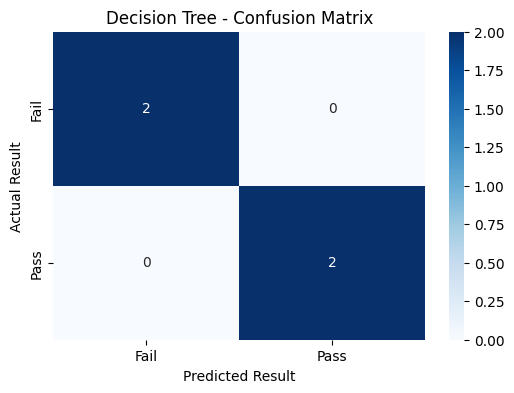

In [10]:

import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Decision Tree - Confusion Matrix")

plt.show()


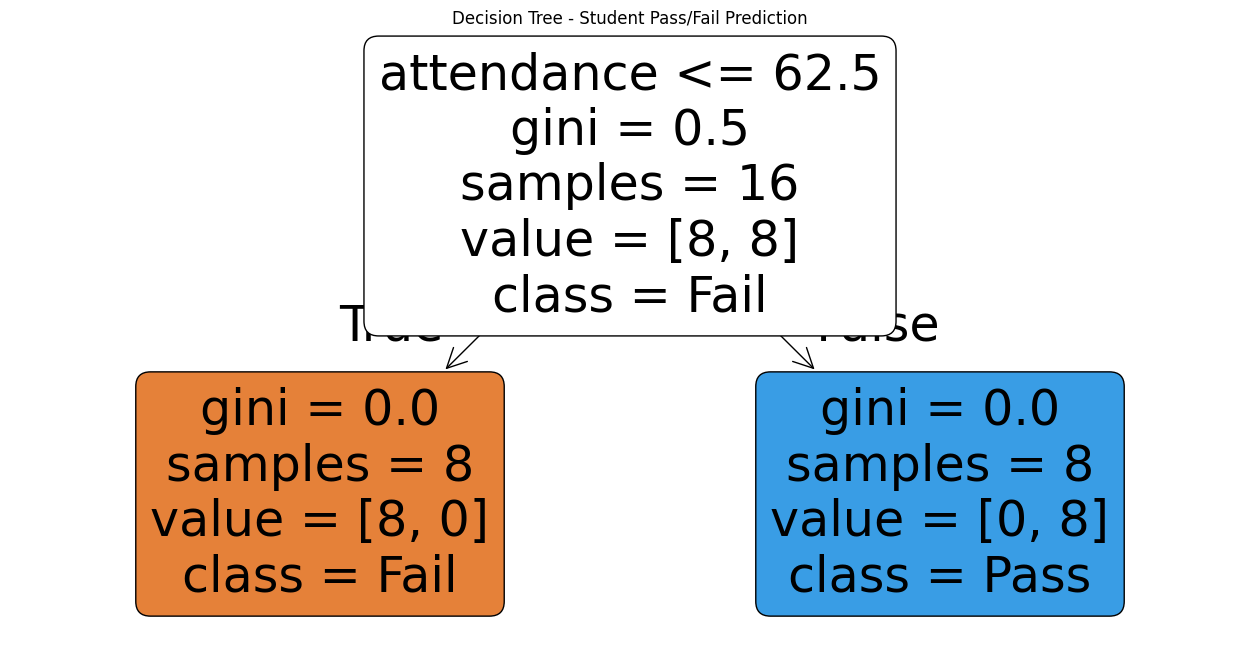

In [11]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Student Pass/Fail Prediction")
plt.show()

In [12]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Fail", "Pass"],
    zero_division=0
))

              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         2
        Pass       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [13]:
new_student = pd.DataFrame({
    "study_hours": [6],
    "attendance": [80],
    "previous_score": [75]
})

prediction = model.predict(new_student)

if prediction[0] == 1:
    print("Predicted Result: PASS")
else:
    print("Predicted Result: FAIL")

Predicted Result: PASS


In [14]:
probabilities = model.predict_proba(new_student)

print("Probability of Fail:", probabilities[0][0] * 100, "%")
print("Probability of Pass:", probabilities[0][1] * 100, "%")

Probability of Fail: 0.0 %
Probability of Pass: 100.0 %


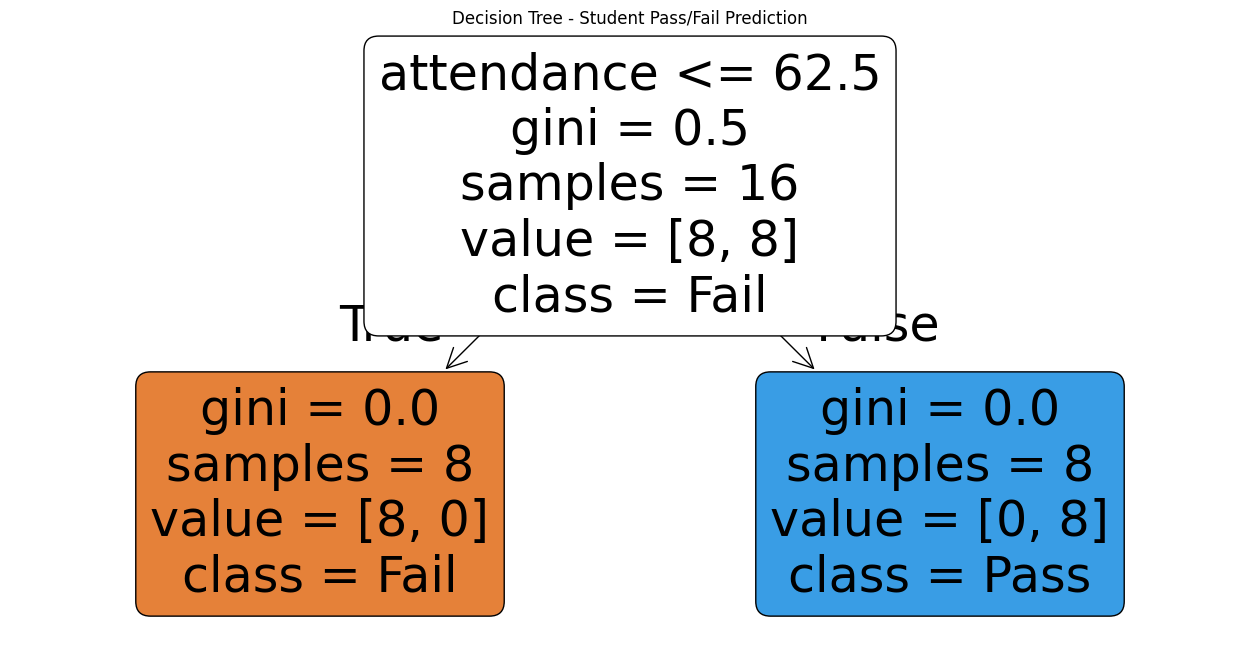

Decision Tree graph saved successfully!


In [15]:
plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Student Pass/Fail Prediction")

plt.savefig("decision_tree.png", dpi=300, bbox_inches="tight")

plt.show()

print("Decision Tree graph saved successfully!")

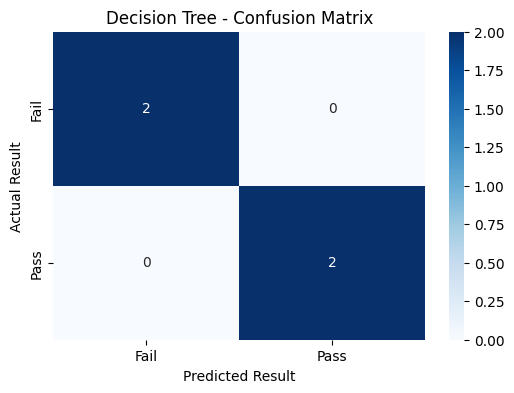

Confusion Matrix graph saved successfully!


In [16]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Decision Tree - Confusion Matrix")

plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")

plt.show()

print("Confusion Matrix graph saved successfully!")

In [18]:
import joblib

In [19]:
joblib.dump(model, "decision_tree_model.pkl")

print("Decision Tree model saved successfully!")

Decision Tree model saved successfully!


In [20]:
loaded_model = joblib.load("decision_tree_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [21]:
df.to_csv("student_dataset.csv", index=False)

print("Student dataset saved successfully!")

Student dataset saved successfully!


In [22]:
results = pd.DataFrame({
    "Actual_Result": y_test.values,
    "Predicted_Result": y_pred
})

results.to_csv("decision_tree_predictions.csv", index=False)

print("Prediction results saved successfully!")

results

Prediction results saved successfully!


,Actual_Result,Predicted_Result
0,0,0
1,0,0
2,1,1
3,1,1


In [23]:
import os

for file in [
    "decision_tree.png",
    "confusion_matrix.png",
    "decision_tree_model.pkl",
    "student_dataset.csv",
    "decision_tree_predictions.csv"
]:
    print(file, "->", "Found" if os.path.exists(file) else "Not found")

decision_tree.png -> Found
confusion_matrix.png -> Found
decision_tree_model.pkl -> Found
student_dataset.csv -> Found
decision_tree_predictions.csv -> Found


In [24]:
readme_content = """
# Student Pass/Fail Prediction Using Decision Tree

## Project Overview
This project uses a Decision Tree Classification algorithm
to predict whether a student will Pass or Fail based on:
- Study Hours
- Attendance
- Previous Score

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib
- Jupyter Notebook

## Machine Learning Workflow
1. Created and inspected the dataset.
2. Separated features and target.
3. Split data into training and testing sets.
4. Trained a Decision Tree Classifier.
5. Evaluated predictions using accuracy, confusion matrix,
   and classification report.
6. Tested the model on a new student.
7. Saved the trained model and project outputs.

## Model Configuration
- Algorithm: Decision Tree Classifier
- Criterion: Gini
- Maximum Depth: 3
- Train/Test Split: 80/20

## Results
- Test samples: 4
- Correct predictions: 4
- Test accuracy: 100%

## Important Limitation
This project uses a small synthetic dataset of 20 students.
The reported accuracy is based on only 4 test samples.
These results do not demonstrate real-world predictive performance.

## Project Files
- Decision_Tree_Classification.ipynb
- decision_tree_model.pkl
- student_dataset.csv
- decision_tree_predictions.csv
- decision_tree.png
- confusion_matrix.png

## Author
BS Physics Student | Machine Learning Learner
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [25]:
with open("README.md", "r", encoding="utf-8") as file:
    print(file.read())


# Student Pass/Fail Prediction Using Decision Tree

## Project Overview
This project uses a Decision Tree Classification algorithm
to predict whether a student will Pass or Fail based on:
- Study Hours
- Attendance
- Previous Score

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib
- Jupyter Notebook

## Machine Learning Workflow
1. Created and inspected the dataset.
2. Separated features and target.
3. Split data into training and testing sets.
4. Trained a Decision Tree Classifier.
5. Evaluated predictions using accuracy, confusion matrix,
   and classification report.
6. Tested the model on a new student.
7. Saved the trained model and project outputs.

## Model Configuration
- Algorithm: Decision Tree Classifier
- Criterion: Gini
- Maximum Depth: 3
- Train/Test Split: 80/20

## Results
- Test samples: 4
- Correct predictions: 4
- Test accuracy: 100%

## Important Limitation
This project uses a small synthetic dataset of 20 students.
The 